# Qwen ESCI v3 LoRA

This notebook reviews the first completed `qwen-esci-v1-lora` Azure ML run. It loads the archived run artifacts, joins scores back to ESCI query/product text, and creates two kinds of examples:

1. **Clean orderings** where the learned score follows `E > S > C > I`.
2. **Review candidates** where scores and labels strongly disagree, plus selected malformed or ambiguous queries.

A disagreement is not automatically a bad label: it can be a model error, an annotation issue, or an ambiguous query. The product text is included so that this distinction can be inspected manually.

In [1]:
import json
import os
from io import BytesIO, StringIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

LABEL_GRADE = {"E": 3, "S": 2, "C": 1, "I": 0}
LABEL_ORDER = ["E", "S", "C", "I"]
TOP_K = 10


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "config/prompts/esci_v1.txt").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the product_reco_gpu_lab project root.")


def find_dataset_dir(project_root: Path) -> Path:
    configured = os.getenv("ESCI_DATA_PATH")
    candidates = [
        Path(configured).expanduser() if configured else None,
        project_root.parent / "ext_repos/esci-data/shopping_queries_dataset",
        project_root / "data/shopping_queries_dataset",
    ]
    for candidate in candidates:
        if candidate is not None and candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate ESCI. Set ESCI_DATA_PATH to shopping_queries_dataset."
    )


PROJECT_ROOT = find_project_root()
DATASET_DIR = find_dataset_dir(PROJECT_ROOT)
RUN_ARCHIVE = Path(
    os.getenv(
        "ESCI_RUN_ARCHIVE",
        PROJECT_ROOT / "run_results/Job_qwen-esci-v3-balanced-mix50-p12-e1-b4-ga8-lr2e-4-r16-s42_OutputsAndLogs.zip",
    )
).expanduser().resolve()

if not RUN_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Run archive not found: {RUN_ARCHIVE}. Set ESCI_RUN_ARCHIVE to override."
    )

print(f"Project root: {PROJECT_ROOT.name}")
print(f"Dataset directory: {DATASET_DIR.name}")
print(f"Run archive: {RUN_ARCHIVE.name}")

Project root: product_reco_gpu_lab
Dataset directory: shopping_queries_dataset
Run archive: Job_qwen-esci-v3-balanced-mix50-p12-e1-b4-ga8-lr2e-4-r16-s42_OutputsAndLogs.zip


In [2]:
with ZipFile(RUN_ARCHIVE) as archive:
    metrics = json.loads(archive.read("evaluation/metrics.json"))
    predictions = pd.read_parquet(
        BytesIO(archive.read("evaluation/predictions.parquet"))
    )
    per_query = pd.read_json(
        StringIO(
            archive.read("evaluation/per_query_metrics.jsonl").decode("utf-8")
        ),
        lines=True,
    )

print(
    f"Loaded {len(predictions):,} scored products across "
    f"{predictions['query_id'].nunique():,} queries."
)

Loaded 20,255 scored products across 1,000 queries.


## 1. Headline results

Precision answers *how clean the first 10 results are*. Recall answers *what fraction of all relevant candidates fit inside those 10 slots*. Consequently, Recall@10 has a hard ceiling below 1 whenever a query has more than 10 relevant candidates.

In [3]:
ranking = metrics["ranking"]
training_epoch = metrics["training"]["epochs"][-1]
headline = pd.DataFrame(
    {
        "value": {
            "NDCG@10": ranking["ndcg@10"],
            "Direct Precision@10 (E/S)": ranking["direct_precision@10"],
            "Direct Recall@10 (E/S)": ranking["direct_recall@10"],
            "Broad Precision@10 (E/S/C)": ranking["broad_precision@10"],
            "Broad Recall@10 (E/S/C)": ranking["broad_recall@10"],
            "Training pair accuracy": training_epoch["pair_accuracy"],
            "Mean RankNet loss": training_epoch["mean_ranknet_loss"],
        }
    }
)
display(headline.style.format({"value": "{:.4f}"}))

direct_counts = per_query["direct_relevant_candidate_count"]
broad_counts = per_query["broad_relevant_candidate_count"]
direct_ceiling = (direct_counts.clip(upper=TOP_K) / direct_counts).mean()
broad_ceiling = (broad_counts.clip(upper=TOP_K) / broad_counts).mean()
ceiling = pd.DataFrame(
    {
        "actual_recall@10": [ranking["direct_recall@10"], ranking["broad_recall@10"]],
        "oracle_recall@10_ceiling": [direct_ceiling, broad_ceiling],
    },
    index=["direct (E/S)", "broad (E/S/C)"],
)
ceiling["fraction_of_ceiling"] = (
    ceiling["actual_recall@10"] / ceiling["oracle_recall@10_ceiling"]
)
display(Markdown("### Recall interpreted against its top-10 ceiling"))
display(ceiling.style.format("{:.4f}"))

,value
NDCG@10,0.8516
Direct Precision@10 (E/S),0.8605
Direct Recall@10 (E/S),0.6344
Broad Precision@10 (E/S/C),0.8933
Broad Recall@10 (E/S/C),0.6123
Training pair accuracy,0.7847
Mean RankNet loss,0.4489


### Recall interpreted against its top-10 ceiling

,actual_recall@10,oracle_recall@10_ceiling,fraction_of_ceiling
direct (E/S),0.6344,0.6990,0.9076
broad (E/S/C),0.6123,0.6626,0.9241


## 2. Join predictions to query and product text

Only the 1,000 evaluated query groups and their product IDs are read from the source Parquet files. No machine-specific absolute path is stored in the notebook.

In [4]:
examples_path = DATASET_DIR / "shopping_queries_dataset_examples.parquet"
products_path = DATASET_DIR / "shopping_queries_dataset_products.parquet"
eval_query_ids = predictions["query_id"].drop_duplicates().astype(int).tolist()
eval_product_ids = predictions["product_id"].drop_duplicates().astype(str).tolist()

examples = pq.read_table(
    examples_path,
    columns=["query_id", "query", "product_id", "product_locale", "esci_label"],
    filters=[
        ("split", "=", "test"),
        ("product_locale", "=", "us"),
        ("query_id", "in", eval_query_ids),
    ],
).to_pandas()
products = pq.read_table(
    products_path,
    columns=[
        "product_id",
        "product_locale",
        "product_title",
        "product_brand",
        "product_color",
    ],
    filters=[
        ("product_locale", "=", "us"),
        ("product_id", "in", eval_product_ids),
    ],
).to_pandas()

example_text = examples.drop_duplicates(["query_id", "product_id"])[
    ["query_id", "query", "product_id", "product_locale", "esci_label"]
]
product_text = products.drop_duplicates(["product_id", "product_locale"])
enriched = predictions.merge(
    example_text, on=["query_id", "product_id"], how="left", validate="one_to_one"
).merge(
    product_text, on=["product_id", "product_locale"], how="left", validate="many_to_one"
)
if not enriched["gold_label"].equals(enriched["esci_label"]):
    raise AssertionError("Archived labels do not match the source ESCI rows.")
enriched["grade"] = enriched["gold_label"].map(LABEL_GRADE)

print(f"Joined rows: {len(enriched):,}")
print(f"Missing titles: {enriched['product_title'].isna().sum():,}")

Joined rows: 20,255
Missing titles: 0


### Aggregate score separation by ESCI label

,products,mean_score,median_score,top_10_rate,mean_rank
gold_label,,,,,
E,9075,1.617,1.578,61.0%,10.85
S,6818,0.445,0.359,45.0%,13.37
C,1010,-1.015,-1.352,32.4%,14.93
I,3352,-1.665,-1.820,31.7%,17.18


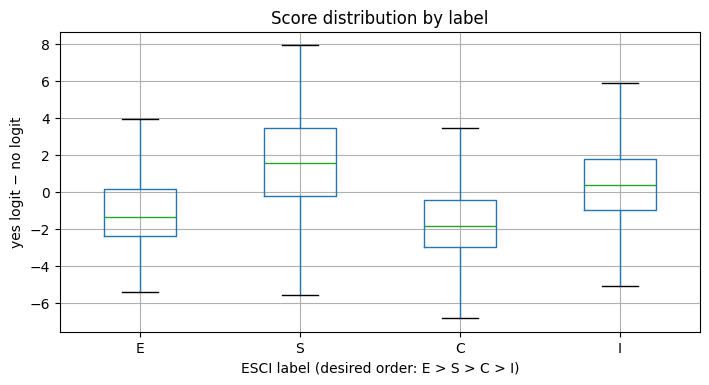

In [5]:
label_summary = (
    enriched.groupby("gold_label", observed=True)
    .agg(
        products=("product_id", "size"),
        mean_score=("ranking_score", "mean"),
        median_score=("ranking_score", "median"),
        top_10_rate=("predicted_rank", lambda values: (values <= TOP_K).mean()),
        mean_rank=("predicted_rank", "mean"),
    )
    .reindex(LABEL_ORDER)
)
display(Markdown("### Aggregate score separation by ESCI label"))
display(
    label_summary.style.format(
        {"mean_score": "{:.3f}", "median_score": "{:.3f}", "top_10_rate": "{:.1%}", "mean_rank": "{:.2f}"}
    )
)

fig, ax = plt.subplots(figsize=(8, 4))
enriched.boxplot(
    column="ranking_score", by="gold_label", positions=range(1, 5), ax=ax, showfliers=False
)
ax.set_xticklabels(LABEL_ORDER)
ax.set_xlabel("ESCI label (desired order: E > S > C > I)")
ax.set_ylabel("yes logit − no logit")
ax.set_title("Score distribution by label")
fig.suptitle("")
plt.show()

## 3. Query-level label ordering

For every query, all differently labeled product pairs are compared. A pair is correct when the product with the higher ESCI grade also has the higher model score. `strict_separation=True` means **every** cross-label pair is correctly separated—not merely that the label means are ordered.

In [6]:
def query_order_statistics(group: pd.DataFrame) -> dict:
    rows = list(group[["gold_label", "ranking_score"]].itertuples(index=False, name=None))
    comparisons = 0
    correct = 0
    worst_inversion_gap = 0.0
    for left_index, (left_label, left_score) in enumerate(rows):
        for right_label, right_score in rows[left_index + 1 :]:
            left_grade = LABEL_GRADE[left_label]
            right_grade = LABEL_GRADE[right_label]
            if left_grade == right_grade:
                continue
            comparisons += 1
            higher_score, lower_score = (
                (left_score, right_score)
                if left_grade > right_grade
                else (right_score, left_score)
            )
            if higher_score > lower_score:
                correct += 1
            else:
                worst_inversion_gap = max(
                    worst_inversion_gap, lower_score - higher_score
                )
    observed_labels = [
        label for label in LABEL_ORDER if label in set(group["gold_label"])
    ]
    label_means = group.groupby("gold_label")["ranking_score"].mean()
    return {
        "query_id": group["query_id"].iloc[0],
        "query": group["query"].iloc[0],
        "candidate_count": len(group),
        "labels_present": "".join(observed_labels),
        "cross_label_pairs": comparisons,
        "pair_order_accuracy": correct / comparisons if comparisons else float("nan"),
        "mean_label_ordered": all(
            label_means[higher] > label_means[lower]
            for higher, lower in zip(observed_labels, observed_labels[1:])
        ),
        "strict_separation": comparisons > 0 and correct == comparisons,
        "worst_inversion_gap": worst_inversion_gap,
    }


def inspection_table(query_ids, max_products_per_query=30):
    columns = [
        "query_id", "query", "predicted_rank", "gold_label",
        "ranking_score", "product_id", "product_title",
        "product_brand", "product_color",
    ]
    selected = enriched[enriched["query_id"].isin(query_ids)].copy()
    selected = selected.sort_values(["query_id", "predicted_rank"])
    return selected.groupby("query_id", sort=False).head(max_products_per_query)[columns]


order_stats = pd.DataFrame(
    query_order_statistics(group)
    for _, group in enriched.groupby("query_id", sort=False)
)
ndcg_column = next(column for column in per_query if column.startswith("ndcg@"))
order_stats = order_stats.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)

display(
    pd.DataFrame(
        {
            "value": {
                "mean same-query pair-order accuracy": order_stats["pair_order_accuracy"].mean(),
                "queries with strict cross-label separation": order_stats["strict_separation"].mean(),
                "queries with all four labels": order_stats["labels_present"].eq("ESCI").mean(),
            }
        }
    ).style.format({"value": "{:.2%}"})
)

,value
mean same-query pair-order accuracy,72.18%
queries with strict cross-label separation,5.50%
queries with all four labels,12.90%


## 4. Strong examples: correct `E > S > C > I` ordering

No evaluated query containing all four labels achieved perfect separation of every individual cross-label product pair. The following are therefore the strongest honest examples: all four **label means** follow `E > S > C > I`, and the queries are ranked by their individual pair-order accuracy. Products with the same label are intentionally unconstrained because the training data gives no preferred order within a label.

In [7]:
good_queries = (
    order_stats[
        order_stats["mean_label_ordered"] & order_stats["labels_present"].eq("ESCI")
    ]
    .sort_values(
        ["pair_order_accuracy", ndcg_column, "candidate_count"],
        ascending=[False, False, False],
    )
    .head(5)
)
display(good_queries.reset_index(drop=True))
display(inspection_table(good_queries["query_id"].tolist()))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10
0,8820,american outdoor grills,16,ESCI,77,0.974026,True,False,0.882812,0.991450
1,63293,logitech crayon for ipad,15,ESCI,76,0.960526,True,False,0.890625,0.985234
2,40337,fimibuke,40,ESCI,429,0.923077,True,False,7.414062,1.000000
3,5722,I would want a light weight protable laptop with a graphics card and alot of memory,39,ESCI,519,0.922929,True,False,4.351562,0.937117
4,1568,10ft umbrella without base,40,ESCI,577,0.875217,True,False,2.953125,1.000000


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
725,1568,10ft umbrella without base,1,E,5.695312,B08V8X943M,FUNWARRIOR 10ft Cantilever Patio Umbrella Square Hanging Outdoor Offset Umbrella 360°Rotation & Integrated Tilting S...,FUNWARRIOR,Wine Red
733,1568,10ft umbrella without base,2,E,5.585938,B08V8HBZ4N,FUNWARRIOR 10ft Cantilever Patio Umbrella Square Hanging Outdoor Offset Umbrella 360°Rotation & Integrated Tilting S...,FUNWARRIOR,Dark Green
747,1568,10ft umbrella without base,3,E,5.195312,B08773746T,"Diophros 10ft Solar Patio Umbrella, 40 LED Lighted Outdoor Table Market Umbrella with 8 Steel Ribs Push Button Tilt ...",Diophros,Green
748,1568,10ft umbrella without base,4,E,4.414062,B087CMJQT6,"10 FT Patio Umbrella with Lights Outdoor Table Market Umbrella with Tilt & Crank,8 Sturdy Ribs(Orange)",Klismos,Orange
724,1568,10ft umbrella without base,5,E,3.476562,B08WZ4VP7F,"Sundale Outdoor 10FT Patio Umbrella Table Umbrella Market Umbrella with Push Button Tilt, Polyester Canopy Shade for...",Sundale,Yellow
...,...,...,...,...,...,...,...,...,...
11335,63293,logitech crayon for ipad,11,C,-1.632812,B072J6VPNT,"Stylus Sling Wide Stylus Holder for Larger Styluses, Compatible with Pencil 53, Logitech Crayon, Bamboo Fineline, 10...",stylus sling,Black
11330,63293,logitech crayon for ipad,12,I,-2.132812,B0827KL26M,ProCase iPad 10.2 Case 2021 iPad 9th Generation/ 2020 iPad 8th Generation/ 2019 iPad 7th Gen Case with Crayon Digita...,ProCase,Black
11326,63293,logitech crayon for ipad,13,C,-2.468750,B07XXRNS5R,Aproca Hard Storage Travel Case for Logitech Crayon Digital Pencil,Aproca,None
11324,63293,logitech crayon for ipad,14,I,-3.218750,B07YN9HY63,"Logitech Rugged Folio - iPad (7th, 8th & 9th generation) Protective Keyboard Case with Smart Connector and Durable S...",Logitech,Graphite


## 5. Strongest score/label inversions

For each query, this finds the single largest inversion: a lower-grade product scoring above a higher-grade product. Large gaps are useful review targets, but the table alone cannot determine whether the model or annotation is wrong.

In [8]:
def worst_inversion(group: pd.DataFrame):
    best = None
    rows = list(group.to_dict("records"))
    for left_index, left in enumerate(rows):
        for right in rows[left_index + 1 :]:
            if left["grade"] == right["grade"]:
                continue
            higher, lower = (left, right) if left["grade"] > right["grade"] else (right, left)
            gap = lower["ranking_score"] - higher["ranking_score"]
            if gap <= 0 or (best is not None and gap <= best["inversion_gap"]):
                continue
            best = {
                "query_id": higher["query_id"],
                "query": higher["query"],
                "inversion_gap": gap,
                "higher_label": higher["gold_label"],
                "higher_score": higher["ranking_score"],
                "higher_title": higher["product_title"],
                "lower_label": lower["gold_label"],
                "lower_score": lower["ranking_score"],
                "lower_title": lower["product_title"],
            }
    return best


inversions = pd.DataFrame(
    inversion
    for _, group in enriched.groupby("query_id", sort=False)
    if (inversion := worst_inversion(group)) is not None
)
inversions = inversions.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)
worst_inversions = inversions.sort_values(
    ["inversion_gap", ndcg_column], ascending=[False, True]
).head(12)
display(worst_inversions.reset_index(drop=True))

display(Markdown("### Full rankings for the five largest inversions"))
display(inspection_table(worst_inversions["query_id"].head(5).tolist()))

,query_id,query,inversion_gap,higher_label,higher_score,higher_title,lower_label,lower_score,lower_title,ndcg@10
0,76433,otterbox 6se phone case,10.289062,E,-3.125000,"OtterBox Defender Series Replacement Holster/Belt Clip for Apple iPhone 5, iPhone 5S, iPhone 5C, iPhone SE (1st GEN ...",I,7.164062,"Otterbox Symmetry Series Case for Iphone 6/6s (4.7"" Version) - Retail Packaging - Prevail (Coral/Gunmetal Grey)",0.779908
1,22422,canon camera,10.015625,E,-5.304688,"Lady house USB Digital Microscope,Sky-Blue,T6 + 18-55mm,33-T6-KITA-111416",S,4.710938,"Canon EOS Rebel T100 DSLR Camera with 18-55mm f/3.5-5.6 Zoom Lens , 64GB Memory,Case, Tripod and More (28pc Bundle)",0.886111
2,36476,easieeaters curved utensils right handed without shields,9.460938,E,-5.085938,"Crimson Trace LG-105 Lasergrips with Red Laser, Heavy Duty Construction and Instinctive Activation for S&W J-Frame R...",I,4.375000,Milestones EasieEaters Curved Fork & Spoon Set - Left Handed,0.818699
3,37126,electric ride on vehicles for kids,9.398438,E,-4.179688,Peg Perego John Deere Ground Force Tractor with Trailer,S,5.218750,"Electric Motorcycle for Kids – 3-Wheel Battery Powered Motorbike for Kids Ages 3 -6 – Fun Decals, Reverse, and Headl...",0.727043
4,32555,designer dupe jewelry,9.019531,E,-5.972656,SOJOS Fashion Square Aviators Sunglasses for Women Flat Mirrored Lens SJ1082 with Gold Frame/Gradient Green&Brown Lens,S,3.046875,PAVOI 14K Rose Gold Plated Sterling Silver CZ Alphabet Letter Earrings | Initial Earrings for Girls | Letter C,0.693017
5,18932,bounce pro 14 ft trampoline enclosure,8.953125,E,-1.851562,Replacement Top Rail without Sockets for the 14' Bounce Pro Flex Models,S,7.101562,Bounce Pro 14 ft Trampoline and Enclosure,0.708845
6,111870,windows 7 professional 64 bit,8.906250,S,-4.554688,"Ralix Windows Emergency Boot Disk - For Windows 98, 2000, XP, Vista, 7, 10 PC Repair DVD All in One Tool (Latest Ver...",I,4.351562,Dell OptiPlex 980 MT/Core i7-860 @ 2.8 GHz/16GB DDR3/500GB HDD/DVD-RW/WINDOWS 7 PRO 64 BIT (Renewed),0.668361
7,110930,white and blue fishing reel,8.757812,S,-2.843750,"Reel Grip 1144 Reel Handle Cover, Patriotic Tie Dye Finish",C,5.914062,"Okuma Fishing TU-702-50 Tundra Combo Spinning Reel (Large, White/Blue)",0.729459
8,1957,128oz lube,8.734375,E,-3.867188,DrinkTanks 128 oz Vacuum Insulated Stainless Steel Beer Growler,S,4.867188,"Wet Original Water Based Sex Lube 128 Ounce Premium Personal Lubricant, Long Lasting Formula for Condom Safe Vegan P...",0.952690
9,10158,architecture without architects,8.609375,E,-3.335938,2G Essays: Kersten Geers: Without Content,I,5.273438,Archigram: Architecture without Architecture (The MIT Press),0.593055


### Full rankings for the five largest inversions

,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
4415,22422,canon camera,1,E,6.273438,B019UDI5PO,Canon PowerShot SX420 Digital Camera w/ 42x Optical Zoom - Wi-Fi & NFC Enabled (Black),Canon,Black
4423,22422,canon camera,2,E,6.078125,B019UDHV6S,Canon Cameras US 1084C001 Canon PowerShot ELPH 190 Digital Camera w/ 10x Optical Zoom and Image Stabilization - Wi-F...,Canon,Black
4418,22422,canon camera,3,E,6.070312,B019UDHOMO,"Canon PowerShot ELPH 180 Digital Camera w/ Image Stabilization and Smart AUTO Mode (Silver), 0.90in. x 3.70in. x 2.1...",Canon,Silver
4428,22422,canon camera,4,E,5.992188,B07FXXVC74,"Canon Cameras US Point and Shoot Digital Camera with 3.0"" LCD, Black (2955C001)",Canon,Black
4420,22422,canon camera,5,E,5.875000,B019UDIAI6,"Canon PowerShot SX540 HS Digital Camera w/ 50x Optical Zoom - Wi-Fi & NFC Enabled (Black), 1 - 1067C001",Canon,Black
...,...,...,...,...,...,...,...,...,...
13666,76433,otterbox 6se phone case,12,E,0.875000,B00F3SIURE,OTTERBOX DEFENDER SERIES Case for iPhone SE (1st gen - 2016) and iPhone 5/5s - Retail Packaging - REALTREE XTRA (BLA...,OtterBox,REALTREE XTRA (BLAZE ORANGE/BLACK W/REALTREE XTRA DESIGN)
13660,76433,otterbox 6se phone case,13,I,0.750000,B01FM0Z3BS,"Lordther iPhone SE Case, [ShieldOn Series] [Military Grade Drop Test] Hybrid Synthetic Rubber TPU Covers with [Scree...",Lordther,Gray
13658,76433,otterbox 6se phone case,14,I,0.289062,B07F17PMR1,"iPhone 5S Case, iPhone 5 Case, iPhone SE (2016) Case, Ankoe Marble Stone Pattern Shockproof Full Body Protective Cov...",Ankoe,Rose Gold
13656,76433,otterbox 6se phone case,15,C,-3.031250,B07NTQMK8G,"AlphaCell Holster Belt Clip Replacement Compatible with OtterBox Defender Series Case for Apple iPhone 5, iPhone 5s,...",AlphaCell,Black


## 6. Curated annotation-quality review cases

These queries were selected after inspecting the low-NDCG tail. Several look malformed, encode exclusions/negation, or appear to have labels that do not match the literal query. They are especially useful for separating ranking failures from dataset noise.

In [9]:
CURATED_REVIEW_NOTES = {
    606: "Malformed query; several E labels appear unrelated to the literal text.",
    33810: "Ambiguous intent: channel/subscription wording versus physical Disney products.",
    74074: "Natural-language complaint/non-shopping query with surprising E annotations.",
    55882: "Explicit 'without cross' constraint; inspect whether labels honor the exclusion.",
    20080: "Explicit 'without envelopes' constraint; useful negation/constraint case.",
}
curated_ids = [query_id for query_id in CURATED_REVIEW_NOTES if query_id in set(enriched["query_id"])]
curated_summary = order_stats[order_stats["query_id"].isin(curated_ids)].copy()
curated_summary["review_reason"] = curated_summary["query_id"].map(CURATED_REVIEW_NOTES)
display(curated_summary.sort_values(ndcg_column).reset_index(drop=True))
display(inspection_table(curated_ids))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10,review_reason
0,606,0zo not bit,33,EI,116,0.258621,False,False,2.406250,0.000000,Malformed query; several E labels appear unrelated to the literal text.
1,55882,jesus without cross,40,ESI,179,0.318436,False,False,2.242188,0.000000,Explicit 'without cross' constraint; inspect whether labels honor the exclusion.
2,74074,no it's not his bike,16,EI,28,0.107143,False,False,4.125000,0.000000,Natural-language complaint/non-shopping query with surprising E annotations.
3,20080,brown notecards without envelopes,40,ESCI,483,0.565217,False,False,2.039062,0.136161,Explicit 'without envelopes' constraint; useful negation/constraint case.
4,33810,disney plus channel,16,EI,15,0.933333,True,False,1.445312,0.630930,Ambiguous intent: channel/subscription wording versus physical Disney products.


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
180,606,0zo not bit,1,I,-1.585938,B06Y1N3PTX,Battleship With Planes Strategy Board Game For Ages 7 and Up (Amazon Exclusive),Hasbro Gaming,None
177,606,0zo not bit,2,I,-1.859375,B00GMXFK3G,"DEWALT Screwdriver Bit Set, Impact Ready, FlexTorq, 40-Piece (DWA2T40IR)",DEWALT,"Black/Silver IMPACT READY FlexTorq Screw Driving Set, 40-Piece"
168,606,0zo not bit,3,I,-1.882812,B07YWRXVP6,"Willful Smart Watch for Android Phones and iOS Phones Compatible iPhone Samsung, IP68 Swimming Waterproof Smartwatch...",Willful,None
164,606,0zo not bit,4,I,-2.125000,B087C1R9QW,"YAMAY Smart Watch, Watches for Men Women Fitness Tracker Blood Pressure Monitor Blood Oxygen Meter Heart Rate Monito...",YAMAY,Pink
169,606,0zo not bit,5,I,-2.195312,B07M9ZF35W,"LEXIVON Torx Bit Socket Set, Premium S2 Alloy Steel | 13-Piece Star T8 - T60 Set | Enhanced Storage Case (LX-143)",LEXIVON,Black
...,...,...,...,...,...,...,...,...,...
13270,74074,no it's not his bike,12,I,-4.125000,B07GGQWQJX,"Laptop Backpack,Travel Computer Bag for Women Men,Anti Theft Water Resistant College School Bookbag,Slim Business Ba...",CAFELE,Black
13280,74074,no it's not his bike,13,E,-4.273438,B00JM5GW10,"Play-Doh Modeling Compound 10-Pack Case of Colors, Non-Toxic, Assorted, 2 oz. Cans, Ages 2 and up, Multicolor (Amazo...",Play-Doh,Multicolor
13277,74074,no it's not his bike,14,I,-4.789062,B01LY3QXGP,"Mancro Laptop Backpack, Business Water Resistant Laptop bag Backpack Gift for Men Women with USB Charging Port, Anti...",Mancro,Austere Grey
13271,74074,no it's not his bike,15,E,-5.226562,B00949CTQQ,"Paulas Choice--SKIN PERFECTING 2% BHA Liquid Salicylic Acid Exfoliant--Facial Exfoliant for Blackheads, Enlarged Por...",Paula's Choice,None


## 7. Manual review sheet

Use this table to record a judgment for each suspicious query. Suggested values are `model_error`, `label_error`, `ambiguous`, and `insufficient_product_text`. The optional export remains commented out so running the notebook does not silently create another artifact.

In [10]:
review_query_ids = list(
    dict.fromkeys(worst_inversions["query_id"].head(12).tolist() + curated_ids)
)
review_sheet = (
    order_stats[order_stats["query_id"].isin(review_query_ids)]
    [["query_id", "query", ndcg_column, "pair_order_accuracy", "worst_inversion_gap"]]
    .sort_values([ndcg_column, "worst_inversion_gap"], ascending=[True, False])
    .copy()
)
review_sheet["reviewer_judgment"] = ""
review_sheet["reviewer_notes"] = ""
display(review_sheet.reset_index(drop=True))

# Optional after filling the fields above:
# review_sheet.to_csv(PROJECT_ROOT / "run_results/qwen_esci_v1_manual_review.csv", index=False)

,query_id,query,ndcg@10,pair_order_accuracy,worst_inversion_gap,reviewer_judgment,reviewer_notes
0,74074,no it's not his bike,0.000000,0.107143,4.125000,,
1,606,0zo not bit,0.000000,0.258621,2.406250,,
2,55882,jesus without cross,0.000000,0.318436,2.242188,,
3,20080,brown notecards without envelopes,0.136161,0.565217,2.039062,,
4,10158,architecture without architects,0.593055,0.607143,8.609375,,
5,33810,disney plus channel,0.630930,0.933333,1.445312,,
6,111870,windows 7 professional 64 bit,0.668361,0.448276,8.906250,,
7,32555,designer dupe jewelry,0.693017,0.358974,9.019531,,
8,18932,bounce pro 14 ft trampoline enclosure,0.708845,0.478261,8.953125,,
9,37126,electric ride on vehicles for kids,0.727043,0.476190,9.398438,,


## Takeaways

- Judge the trained run against the unmodified-Qwen baseline produced by `python jobs/submit_train_esci.py --eval-only`; absolute trained metrics alone do not measure improvement.
- Recall@10 should be read relative to its query-specific ceiling, because many ESCI queries have more than 10 relevant candidates.
- Aggregate score means can follow `E > S > C > I` while individual products still overlap substantially. Query-level pair accuracy and inversion examples expose that overlap.
- Do not automatically train harder on the suspicious cases. First classify them as model errors, annotation errors, ambiguous intent, or insufficient product text.